## 作业2 python例程

样本读取，绘图函数已写好。

要求：编写SVM函数并绘图。

In [2422]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
# from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

df = pd.read_csv('iris.data.txt', header=0)
data = df.values[:,:2]

划分数据函数split_data()，详情参见注释

In [2423]:
def split_data(data, test_size=0.25, random_state=None):
    """
    将数据划分为训练集和测试集

    参数:
    data: numpy数组, 形状为 [n_samples, n_features]，包含特征数据
    test_size: 测试集占总样本的比例, 默认为0.25
    random_state: 随机数种子, 默认为None

    返回值:
    X_train: 训练集特征
    X_test: 测试集特征
    y_train: 训练集标签
    y_test: 测试集标签
    """
    labels = np.zeros(data.shape[0])
    labels[50:] = 1
    X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=test_size, random_state=random_state)
    return X_train, X_test, y_train, y_test


### 接下来是你唯一需要修改的函数。

请使用自己编写的算法取代里面用到的现成SVM模型。

需要预测y_predict，计算得到k、b，以及支撑向量。

In [2424]:
class MySVM:
    def __init__(self, kernal='linear', C=1.0, pre_calc=False):
        # 初始化参数
        self.kernel = 'linear'
        self.bias_ = 0
        self.alpha_ = None
        self.support_vectors_ = None
        self.support_labels_ = None

        self._C = C

        if self.kernel == 'linear':
            self.kernel_func = self._kernel_linear
        else:
            raise ValueError("Unsupported kernel type")

    @staticmethod
    def _kernel_linear(x1, x2):
        # 线性核函数
        return x1 @ x2.T

    def fit(self, x, y, max_iter=3000, tol=1e-7):
        # SMO算法
        _y = np.where(y == 0, -1, 1)
        m, n = x.shape
        _alphas = np.zeros(x.shape[0])  # 样本加权的优化变量，初始值为0

        def _calc_error(i):
            # 计算第i个样本的误差E_i = f(x_i) - y_i

            # 计算分类函数 f(x_i) = sum(alpha_j * y_j * K(x_j, x_i)) + b
            f_xi = np.dot(_alphas * _y, K_cache[:, i]) + self.bias_
            return f_xi - _y[i]

        def _select_alpha_j(i, error_i):
            # 根据已选的alpha, 选择第二个优化变量alpha_j, 使得Ei - Ej最大，保证两个alpha的更新幅度尽可能大（偏离度）

            # 初始化
            j, error_j, delta = -1, 0, 0
            gt_zero = np.where(_alphas > 0)[0]

            if len(gt_zero) > 1:
                for k in gt_zero:
                    if k == i:
                        # 跳过第i个样本
                        continue
                    error_k = _calc_error(k)
                    delta_k = abs(error_i - error_k)
                    if delta_k > delta:
                        j, error_j, delta = k, error_k, delta_k
            else:
                j = np.random.choice([n for n in range(x.shape[0]) if n != i])
                error_j = _calc_error(j)

            return j, error_j

        # 核函数值缓存
        K_cache = np.zeros((m, m))
        for i in range(m):
            for j in range(m):
                K_cache[i, j] = self.kernel_func(x[i], x[j])

        # 训练模型
        iteration = 0
        flag_alpha_changed_count = 5  # 连续5次迭代没有alpha被更新，认为模型已经收敛
        while iteration < max_iter:
            iteration += 1
            flag_alpha_changed = 0
            for i in range(m):
                error_i = _calc_error(i)


                # 判断alpha_i是否满足KKT条件
                if ((_y[i] * error_i < -tol and _alphas[i] < self._C)
                    or (_y[i] * error_i > tol and _alphas[i] > 0)):

                    # 选择第二个优化变量alpha_j
                    j, error_j = _select_alpha_j(i, error_i)

                    # 保存更新前的alpha值
                    alpha_i_old, alpha_j_old = _alphas[i], _alphas[j]
                    bias_old = self.bias_
                    # 计算alpha_j的更新范围，保证更新后的alpha_j满足约束条件0 <= alpha_j <= C
                    if _y[i] != _y[j]:
                        L = max(0,       alpha_j_old - alpha_i_old)
                        H = min(self._C, self._C + alpha_j_old - alpha_i_old)
                    else:
                        L = max(0,       alpha_j_old + alpha_i_old - self._C)
                        H = min(self._C, alpha_j_old + alpha_i_old)

                    if L == H:
                        # 如果更新范围无效，跳过该样本
                        continue

                    # 计算eta
                    eta = 2.0 * K_cache[i, j] - K_cache[i, i] - K_cache[j, j]
                    if eta >= 0:
                        continue

                    # 更新alpha_j
                    _alphas[j] -= _y[j] * (error_i - error_j) / eta
                    _alphas[j] = np.clip(_alphas[j], L, H)

                    _delta_alpha_j = _alphas[j] - alpha_j_old
                    if abs(_delta_alpha_j) < tol:
                        continue

                    # 更新alpha_i
                    _alphas[i] += _y[i] * _y[j] * (alpha_j_old - _alphas[j])
                    _delta_alpha_i = _alphas[i] - alpha_i_old

                    # 更新b
                    b1 = self.bias_ - error_i - _y[i] * (K_cache[i, i] * (_delta_alpha_i)) - _y[j] * (K_cache[j, i] * (_delta_alpha_j))
                    b2 = self.bias_ - error_j - _y[i] * (K_cache[i, j]  * (_delta_alpha_i)) - _y[j] * (K_cache[j, j] * (_delta_alpha_j))

                    if 0 < _alphas[i] < self._C:
                        self.bias_ = b1
                    elif 0 < _alphas[j] < self._C:
                        self.bias_ = b2
                    else:
                        self.bias_ = (b1 + b2) / 2.0

                    flag_alpha_changed = 1

            if flag_alpha_changed == 0:
                flag_alpha_changed_count -= 1
                if flag_alpha_changed_count == 0:
                    # 如果没有alpha被更新，说明模型已经收敛，可以停止训练
                    print(f"SVM converged after {iteration - 5} iterations")
                    break
        else:
            print("Warning: SVM did not converge within the maximum number of iterations")

        sv = _alphas > 1e-6

        self.support_vectors_ = x[sv]
        self.support_labels_ = _y[sv]
        self.alpha_ = _alphas[sv]

    def predict(self, X):
        # K: (n_sv, n_samples)
        K = self.kernel_func(self.support_vectors_, X)

        decision = (
            (self.alpha_ * self.support_labels_) @ K + self.bias_
        )

        return np.where(decision >= 0, 1, 0)

def svm_process(X_train, y_train, X_test, y_test):
    """
    使用自编写的线性SVM训练模型, 并得到分类函数的参数和支撑向量

    参数:
    X_train: 训练集特征
    y_train: 训练集标签
    X_test: 测试集特征
    y_test: 测试集标签(用于计算准确率)

    返回值:
    k: 分类函数的斜率
    b: 分类函数的截距
    support_vectors: 支撑向量
    """
    # My SVM implementation

    # reference predict result
    svm = MySVM(kernal = 'linear')
    svm.fit(X_train, y_train)

    y_predict = svm.predict(X_test) ###这一步作为中间变量，虽然不需要传递但必须要计算。

    accuracy = accuracy_score(y_test, y_predict) ###比较你的y_predict与真实标签y_text

    print("Accuracy: ", accuracy)

    ### 得到线性分类函数的参数。自己编写时直接计算即可。
    k = svm.alpha_ * svm.support_labels_ @ svm.support_vectors_
    b = svm.bias_

    ### 需计算得到支撑向量们
    support_vectors = svm.support_vectors_

    return k, b, support_vectors


In [2425]:

def plot_results(k, b, support_vectors, X_test, y_test):
    """
    绘制分类结果图

    参数:
    k: 分类函数的斜率
    b: 分类函数的截距
    support_vectors: 支撑向量
    X_test: 测试集特征
    y_test: 测试集标签
    """

    # 画出结果图
    plt.style.use("default")
    plt.figure(figsize=(10, 6))
    # 绘制测试集样本
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', edgecolors='k', s=70, label='test samples')
    # 绘制支撑向量点
    plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=200, linewidth=1, facecolors='none', edgecolors='k', label='support vectors')
    
    # 绘制分类函数
    xx = np.linspace(X_test[:, 0].min(), X_test[:, 0].max())
    yy = - (k[0] / k[1]) * xx - (b / k[1])
    plt.plot(xx, yy, 'k-', label='cls function')
    
    plt.title('SVM Classification Results')
    plt.legend()
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()


In [2426]:
X_train, X_test, y_train, y_test = split_data(data)


In [2427]:
### 帮助理解各样本的形状

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(111, 2)
(111,)
(38, 2)
(38,)


In [2428]:
k, b, support_vectors = svm_process(X_train, y_train, X_test,y_test)

SVM converged after 1 iterations
Accuracy:  0.9736842105263158


In [2429]:
### 上面得到的准确率，以及这三项可能会因样本点的随机性而在一定范围内变化
print(k)
print(b)
### 支撑向量个数，内容也可能改变
print(support_vectors.shape)

[1.232067547984502 -1.4455032088250084]
-2.2217895483985366
(7, 2)


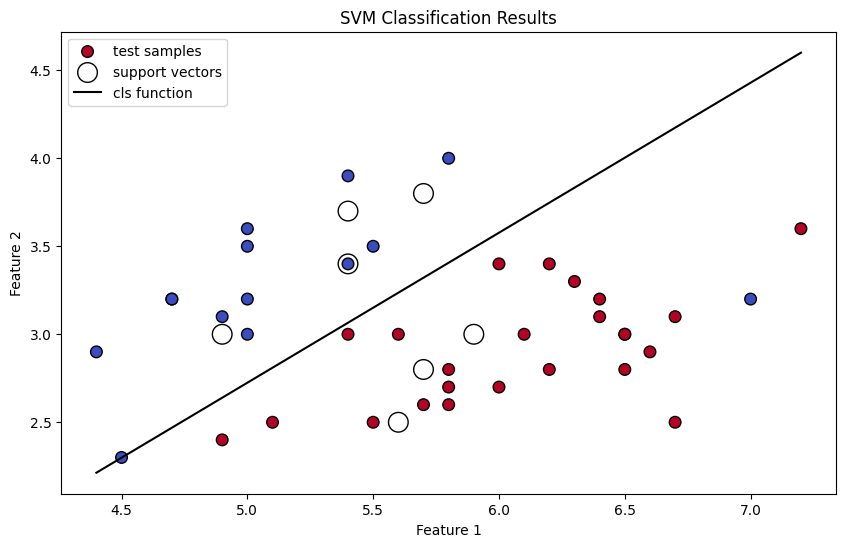

In [2430]:
plot_results(k, b, support_vectors, X_test, y_test)
